# SimSys Local · Fase 2 · Notebook 03
## Grafo de similitud y detección de comunidades

La fase 1 dejó calculada la similitud de todos los pares. Aquí esos pares se convierten en un **grafo**
(entidades = nodos, similitud alta = arista) y se buscan **comunidades**: grupos de entidades más conectadas
entre sí que con el resto. Serán la base del recomendador de la fase 3.

1. **¿Cómo construir el grafo?** Barrido de umbral global y de k vecinos más cercanos.
2. **Elección** con un criterio no supervisado: cobertura, estabilidad y modularidad.
3. **Comunidades** con Leiden y caché versionada del grafo (`GraphManager`).
4. **Comparación**: configuración original (umbral 84 + Louvain), Louvain, K-Means, K-Prototypes y HDBSCAN.
5. **Interpretación**: perfil de cada comunidad, cruce con los segmentos simulados y proyección 2D.

> Requiere haber ejecutado la fase 1 con la métrica *hybrid* (`python main_fase1.py` o el notebook 02).
> Cambia `PROYECTO` para ver el otro dataset. Tarda unos 2 minutos.

In [1]:
import sys, time, warnings
from pathlib import Path
warnings.filterwarnings("ignore", category=FutureWarning)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import config
from simsys import DataPreprocessor, LocalStage, GraphManager
from simsys.graph_manager import threshold_graph, knn_graph, top_k_neighbors
from simsys.communities import (threshold_sweep, knn_sweep, select_configuration, production_reference,
                                compare_graph_methods, relabel_by_size, profile_communities,
                                community_segment_crosstab, RESTO)
from simsys.baselines import run_baselines
from simsys.axis_similarity import dense_similarity

pd.set_option("display.max_columns", 50); pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 160)
plt.rcParams["figure.dpi"] = 110

## 0. Parámetros

In [2]:
PROYECTO = "CLIENTES"
P2 = config.FASE2                       # umbrales, ks, semillas, criterios… (config.py)
cfg = config.PROYECTOS[PROYECTO]
ID, METRICA, EJE = cfg["id"], P2["metrica"], P2["eje"]
MIN_SIZE, SEEDS = P2["tam_min_comunidad"], P2["semillas"]

stage = LocalStage(config.STAGE_DIR)
df = pd.read_excel(cfg["fichero"])
ids = np.sort(df[ID].to_numpy())
segments = df.set_index(ID)[cfg["columna_validacion"]]
truth = segments.loc[ids].to_numpy()        # SOLO para validación externa, nunca para elegir parámetros
print(f"{PROYECTO}: {len(ids):,} entidades · similitudes de {stage.latest_dir(PROYECTO, METRICA, EJE).relative_to(config.BASE_DIR)}")

CLIENTES: 10,000 entidades · similitudes de output/stage/CLIENTES/hybrid/General/2026/09/30


## 1. ¿Cómo construir el grafo?

Hay dos formas habituales de pasar de similitudes a aristas:

- **Umbral global**: arista si $S(a,b) \ge u$. Es lo que hace producción, con $u = 84$. Problema: las entidades
  cuyo vecino más parecido está por debajo de $u$ quedan **aisladas**, sin comunidad y sin posibilidad de recomendación.
- **k vecinos más cercanos (kNN)**: cada entidad se conecta a sus $k$ más similares. Nadie queda aislado y la densidad
  se adapta a cada zona del espacio.

Para cada configuración se detectan comunidades con Leiden y se mide:

| Métrica | Qué mide | Tipo |
|---|---|---|
| Cobertura | % de entidades en comunidades de al menos `MIN_SIZE` miembros | No supervisada |
| Modularidad (Q) | Cuánto más densas son las comunidades por dentro que entre ellas | No supervisada |
| Estabilidad | ARI medio entre las particiones de 5 semillas (1 = siempre la misma) | No supervisada |
| ARI / NMI | Acuerdo con el segmento simulado | **Externa**: solo para validar |

In [3]:
t0 = time.time()
pairs = stage.load_latest(PROYECTO, METRICA, EJE, min_similarity=min(P2["umbrales"]))
print(f"{len(pairs):,} pares con similitud >= {min(P2['umbrales'])} ({time.time() - t0:.1f}s)\n")
sweep_u = threshold_sweep(pairs, ids, P2["umbrales"], truth, SEEDS, MIN_SIZE, P2["resolucion"])

1,436,223 pares con similitud >= 70 (1.2s)



  umbral  70: aristas=1,436,223  aislados=0.2%  comunidades=  7  cobertura=99.8%  Q=0.661  estab=0.996


  umbral  72: aristas=1,078,572  aislados=0.5%  comunidades=  7  cobertura=99.5%  Q=0.672  estab=0.998


  umbral  74: aristas=  772,612  aislados=1.2%  comunidades=  9  cobertura=98.6%  Q=0.683  estab=0.991


  umbral  76: aristas=  522,788  aislados=2.6%  comunidades= 11  cobertura=96.9%  Q=0.692  estab=0.983


  umbral  78: aristas=  329,230  aislados=5.2%  comunidades=  9  cobertura=93.5%  Q=0.704  estab=0.935


  umbral  80: aristas=  190,394  aislados=9.9%  comunidades= 11  cobertura=88.4%  Q=0.715  estab=0.957


  umbral  82: aristas=   99,370  aislados=17.0%  comunidades= 11  cobertura=79.3%  Q=0.732  estab=0.989


  umbral  84: aristas=   45,958  aislados=28.5%  comunidades= 14  cobertura=66.5%  Q=0.747  estab=0.918


  umbral  86: aristas=   18,878  aislados=43.6%  comunidades= 15  cobertura=49.0%  Q=0.774  estab=0.960


In [4]:
t0 = time.time()
knn_sim, knn_idx = top_k_neighbors(stage, PROYECTO, METRICA, EJE, ids, max(P2["ks"]))
print(f"k vecinos calculados en {time.time() - t0:.1f}s")
print(f"Similitud mediana del 1.er vecino: {np.median(knn_sim[:, 0]):.0f} · del 15.º: {np.median(knn_sim[:, 14]):.0f}\n")
sweep_k = knn_sweep(knn_sim, knn_idx, ids, P2["ks"], truth, SEEDS, MIN_SIZE, P2["resolucion"])

k vecinos calculados en 32.1s
Similitud mediana del 1.er vecino: 86 · del 15.º: 80



  k =   5:     aristas=   37,615  aislados=0.0%  comunidades= 11  cobertura=100.0%  Q=0.806  estab=0.770


  k =  10:     aristas=   73,522  aislados=0.0%  comunidades= 12  cobertura=100.0%  Q=0.784  estab=0.867


  k =  15:     aristas=  109,017  aislados=0.0%  comunidades= 11  cobertura=100.0%  Q=0.777  estab=0.935


  k =  20:     aristas=  144,355  aislados=0.0%  comunidades= 11  cobertura=100.0%  Q=0.770  estab=0.949


  k =  30:     aristas=  214,399  aislados=0.0%  comunidades=  9  cobertura=100.0%  Q=0.756  estab=0.890


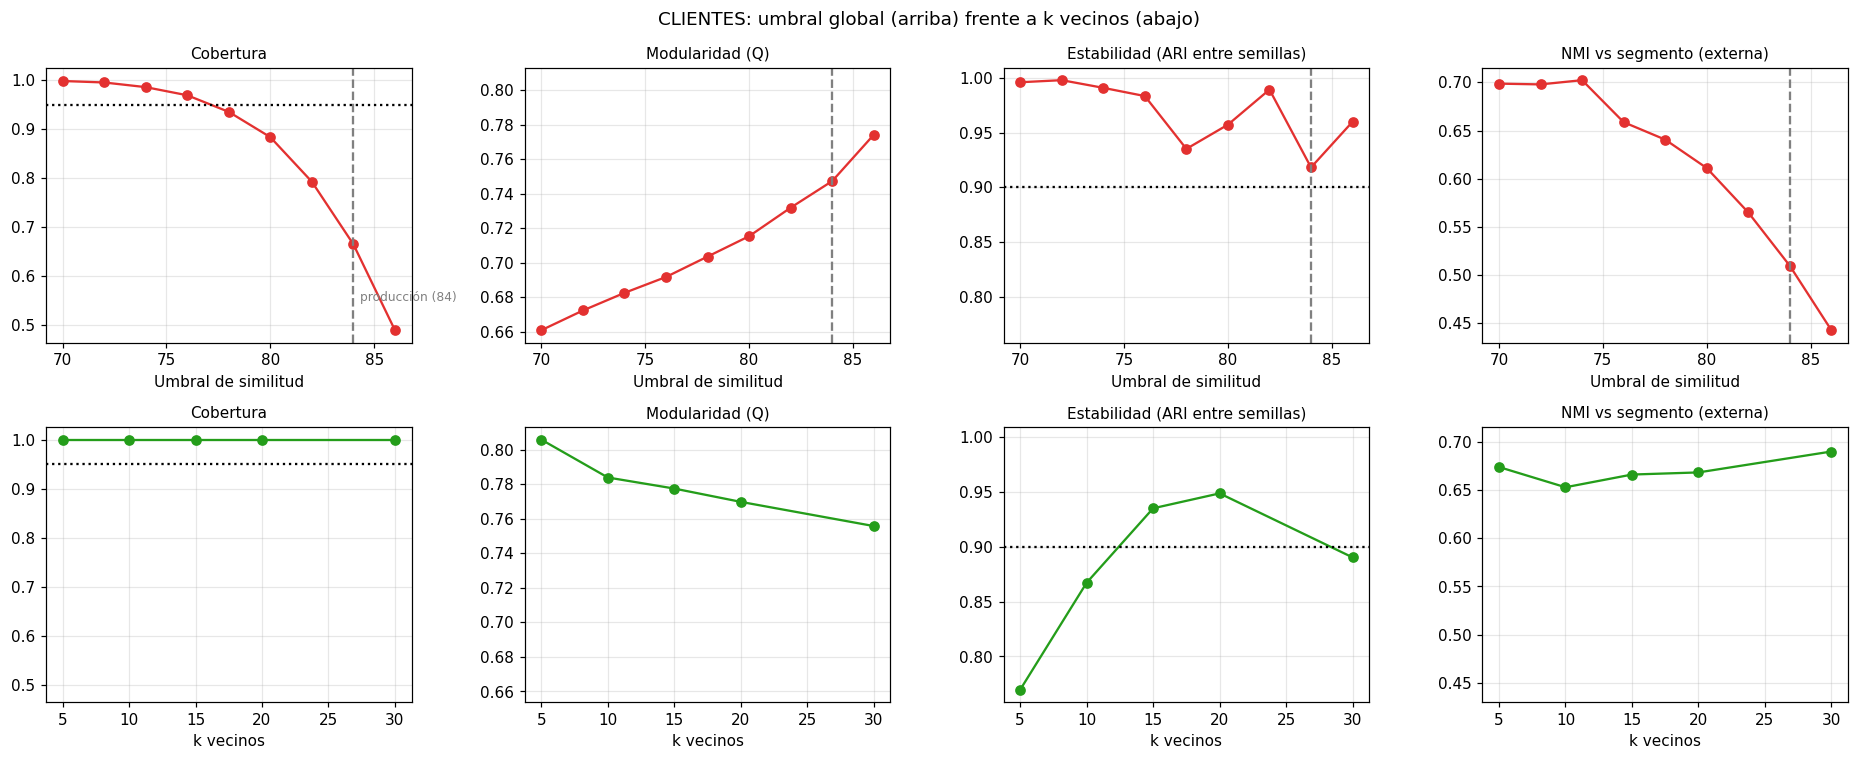

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(17, 7), sharey="col")
metricas = [("cobertura", "Cobertura"), ("modularidad", "Modularidad (Q)"),
            ("estabilidad", "Estabilidad (ARI entre semillas)"), ("NMI", "NMI vs segmento (externa)")]
for row, (sw, xl, color) in enumerate([(sweep_u, "Umbral de similitud", "#E33130"), (sweep_k, "k vecinos", "#249D1A")]):
    for col, (m, titulo) in enumerate(metricas):
        ax = axes[row, col]
        ax.plot(sw["parametro"], sw[m], "o-", color=color)
        ax.set_title(titulo, fontsize=10); ax.set_xlabel(xl); ax.grid(alpha=0.3)
        if row == 0:
            ax.axvline(P2["umbral_original"], ls="--", c="grey")
        if m == "cobertura":
            ax.axhline(P2["cobertura_minima"], ls=":", c="black")
        if m == "estabilidad":
            ax.axhline(P2["estabilidad_minima"], ls=":", c="black")
axes[0, 0].text(P2["umbral_original"] + 0.3, 0.55, "producción (84)", color="grey", fontsize=8)
fig.suptitle(f"{PROYECTO}: umbral global (arriba) frente a k vecinos (abajo)", fontsize=12)
plt.tight_layout(); plt.show()

**Cómo leerlo.** Subir el umbral hace el grafo más "limpio" (más modularidad), pero cada punto de umbral deja
fuera a más entidades: con 84 queda aislado entre un cuarto y un tercio del total. El grafo kNN mantiene la cobertura en el 100 %
con muchas menos aristas y una modularidad mayor.

## 2. Elección de la configuración (criterio no supervisado)

1. Cobertura ≥ 95 %.
2. Estabilidad ≥ 0,90.
3. Entre las que cumplen, **máxima modularidad** (desempate: menos aristas).

Solo con estabilidad no bastaría: crece al densificar el grafo porque las comunidades se fusionan, y el criterio
acabaría eligiendo siempre el umbral más bajo. El segmento simulado **no interviene**: con datos reales no existiría.

In [6]:
sweep = pd.concat([sweep_u, sweep_k], ignore_index=True)
elegido = select_configuration(sweep, P2["cobertura_minima"], P2["estabilidad_minima"])
print(f"Configuración elegida: {elegido['grafo']} = {elegido['parametro']}")

def resaltar(row):
    es = (row["grafo"] == elegido["grafo"]) and (row["parametro"] == elegido["parametro"])
    return ["background-color: #d9f2d9" if es else "" for _ in row]

(sweep[["grafo", "parametro", "aristas", "grado_medio", "pct_aislados", "comunidades", "cobertura",
        "modularidad", "estabilidad", "ARI", "NMI"]]
 .style.apply(resaltar, axis=1).format(precision=3).format("{:,}", subset=["aristas"]))

Configuración elegida: knn = 15


,grafo,parametro,aristas,grado_medio,pct_aislados,comunidades,cobertura,modularidad,estabilidad,ARI,NMI
0,umbral,70,"1,436,223",287.240,0.002,7,0.998,0.661,0.996,0.611,0.699
1,umbral,72,"1,078,572",215.710,0.005,7,0.995,0.672,0.998,0.613,0.698
2,umbral,74,"772,612",154.520,0.012,9,0.986,0.683,0.991,0.622,0.702
3,umbral,76,"522,788",104.560,0.026,11,0.969,0.692,0.983,0.522,0.659
4,umbral,78,"329,230",65.850,0.052,9,0.935,0.704,0.935,0.516,0.641
5,umbral,80,"190,394",38.080,0.099,11,0.884,0.715,0.957,0.488,0.611
6,umbral,82,"99,370",19.870,0.170,11,0.793,0.732,0.989,0.439,0.565
7,umbral,84,"45,958",9.190,0.285,14,0.665,0.747,0.918,0.349,0.510
8,umbral,86,"18,878",3.780,0.436,15,0.490,0.774,0.960,0.167,0.443
9,knn,5,"37,615",7.520,0.000,11,1.000,0.806,0.770,0.603,0.674


## 3. Grafo final y comunidades (Leiden)

`GraphManager` es la versión local del gestor de grafos del sistema original: calcula las comunidades, guarda grafo
y metadatos en `output/graphs/<PROYECTO>/<metrica>/GRAPH_COMMUNITIES/<version>/` y, en ejecuciones posteriores,
los carga de la caché sin recalcular. La fase 3 partirá de aquí.

In [7]:
g = (knn_graph(ids, knn_sim, knn_idx, int(elegido["parametro"])) if elegido["grafo"] == "knn"
     else threshold_graph(pairs, ids, int(elegido["parametro"])))

manager = GraphManager(config.GRAPHS_DIR, PROYECTO, METRICA)
g, communities, membership, mapping, reverse_mapping = manager.compute_or_load(
    graph=g, method="leiden", seed=SEEDS[0], resolution=P2["resolucion"], version=P2["version_grafo"],
    force_recompute=True, extra={"grafo": elegido["grafo"], "parametro": int(elegido["parametro"])})

# Demostración de la caché: segunda llamada sin grafo -> se carga de disco
_ = manager.compute_or_load(version=P2["version_grafo"])

etiquetas = pd.Series(relabel_by_size(membership, MIN_SIZE), index=ids, name="COMUNIDAD")
print(f"\nComunidades útiles (>= {MIN_SIZE} entidades): {etiquetas[etiquetas != RESTO].nunique()} · "
      f"entidades en 'Resto': {(etiquetas == RESTO).sum()}")

🔄 Comunidades (leiden) calculadas en 0.12s
💾 Grafo guardado en graphs/CLIENTES/hybrid/GRAPH_COMMUNITIES/v1 (10,000 nodos, 109,017 aristas, 11 comunidades)


📂 Grafo 'v1' cargado en 0.04s (10,000 nodos, 11 comunidades)
📂 Grafo 'v1' cargado en 0.04s (10,000 nodos, 11 comunidades)

Comunidades útiles (>= 20 entidades): 11 · entidades en 'Resto': 0


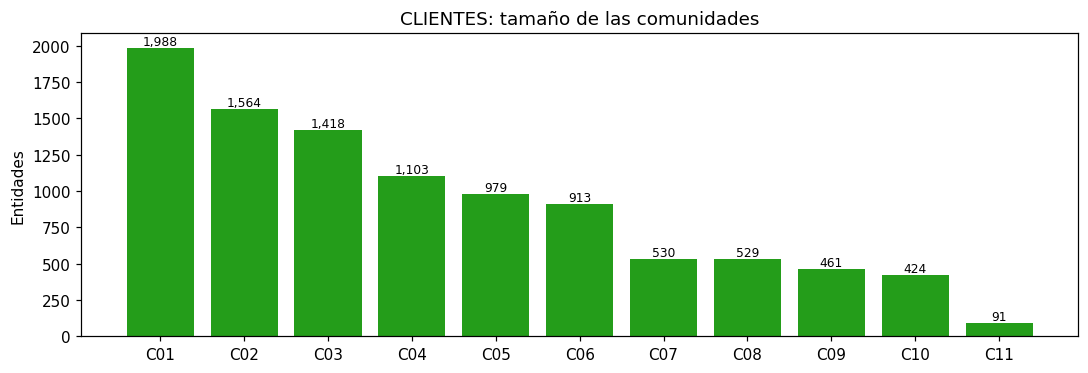

In [8]:
tam = etiquetas.value_counts()
tam = tam.reindex([c for c in tam.index if c != RESTO] + ([RESTO] if RESTO in tam.index else []))
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(tam.index, tam.values, color=["#249D1A" if c != RESTO else "lightgrey" for c in tam.index])
for i, v in enumerate(tam.values):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=8)
ax.set_title(f"{PROYECTO}: tamaño de las comunidades"); ax.set_ylabel("Entidades")
plt.tight_layout(); plt.show()

## 4. Comparación de métodos

- **Original**: umbral 84 + Louvain, y solo con los nodos que aparecen en algún par, como en producción.
- **Leiden / Louvain** sobre el grafo elegido.
- **Clustering clásico** sobre los mismos datos preprocesados. K-Means y K-Prototypes reciben el número **real**
  de perfiles (8), así que son una referencia optimista. HDBSCAN decide solo su número de grupos, como el grafo.

In [9]:
ref = production_reference(pairs, ids, truth, P2["umbral_original"], MIN_SIZE, SEEDS[0])
comp_graph = compare_graph_methods(g, truth, SEEDS, MIN_SIZE, P2["resolucion"])
comp_graph["metodo"] = comp_graph["metodo"] + f" · {elegido['grafo']} {elegido['parametro']}"

prep = DataPreprocessor("StandardScaler", [METRICA], ID, cfg["excluir"])
prep.fit_transform(df)
X = prep.processed_data.loc[ids]
num, cat = prep.columns_of_type("numeric"), prep.columns_of_type("categorical", "boolean")
bl = run_baselines(X, num, cat, int(pd.Series(truth).nunique()), truth,
                   P2["baselines"]["hdbscan_pca"], P2["baselines"]["hdbscan_min_cluster"], P2["baselines"]["kprototypes"])

comparativa = pd.concat([pd.DataFrame([ref]), comp_graph,
                         pd.DataFrame([{k: v for k, v in r.items() if k != "labels"} for r in bl.values()])],
                        ignore_index=True)
comparativa[["metodo", "familia", "comunidades", "cobertura", "pct_fuera_del_grafo", "modularidad",
             "estabilidad", "ARI", "NMI", "segundos"]]

  K-Means (k=8)                grupos=  8  cobertura=100.0%  ARI=0.546  NMI=0.682  (0.4s)


  K-Prototypes (k=8)           grupos=  8  cobertura=100.0%  ARI=0.543  NMI=0.679  (21.1s)


  HDBSCAN (PCA 5)              grupos=  2  cobertura=76.3%  ARI=0.124  NMI=0.240  (0.6s)


,metodo,familia,comunidades,cobertura,pct_fuera_del_grafo,modularidad,estabilidad,ARI,NMI,segundos
0,Original: umbral 84 + Louvain,Grafo,14,0.6640,0.2848,0.7429,NaN,0.3478,0.5084,0.07
1,Leiden · knn 15,Grafo,11,1.0000,0.0000,0.7774,0.9352,0.5921,0.6661,0.15
2,Louvain · knn 15,Grafo,10,1.0000,0.0000,0.7723,0.8968,0.6057,0.6787,0.21
3,K-Means (k=8),Clustering clásico,8,1.0000,NaN,NaN,NaN,0.5460,0.6823,0.42
4,K-Prototypes (k=8),Clustering clásico,8,1.0000,NaN,NaN,NaN,0.5428,0.6795,21.13
5,HDBSCAN (PCA 5),Clustering clásico,2,0.7629,NaN,NaN,NaN,0.1237,0.2402,0.58


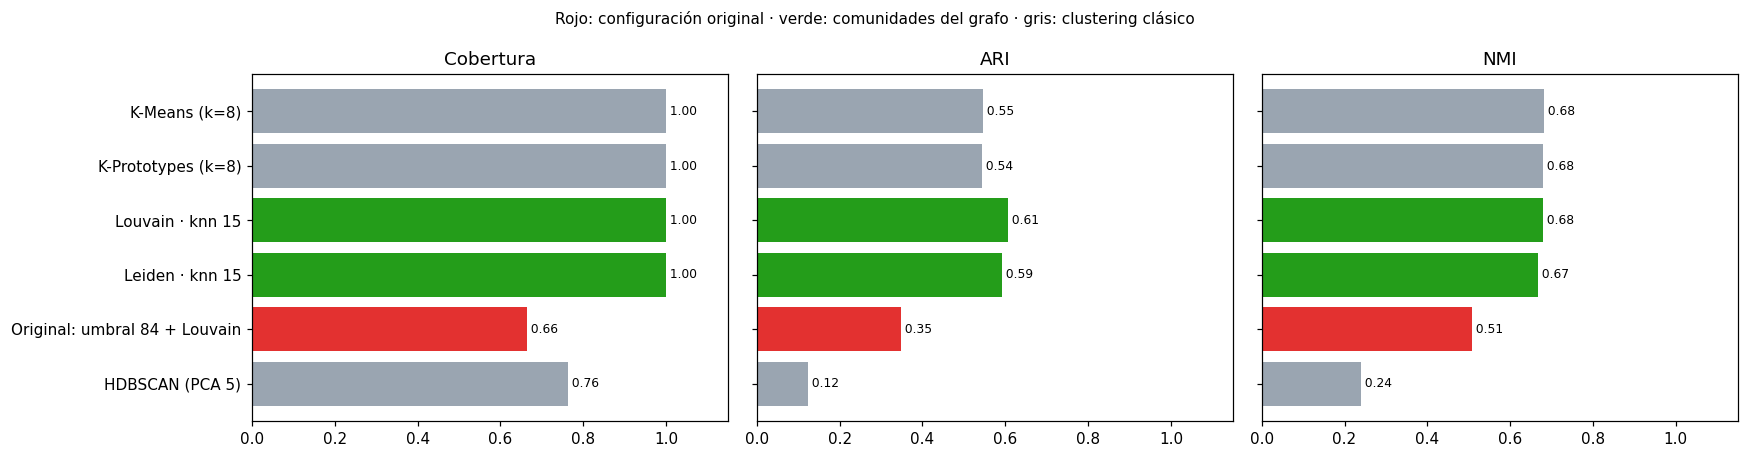

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
orden = comparativa.sort_values("NMI")
colores = ["#E33130" if m.startswith("Original") else "#249D1A" if f == "Grafo" else "#9aa5b1"
           for m, f in zip(orden["metodo"], orden["familia"])]
for ax, m in zip(axes, ["cobertura", "ARI", "NMI"]):
    ax.barh(orden["metodo"], orden[m], color=colores)
    for i, v in enumerate(orden[m]):
        ax.text(v, i, f" {v:.2f}", va="center", fontsize=8)
    ax.set_title(m if m != "cobertura" else "Cobertura"); ax.set_xlim(0, 1.15)
fig.suptitle("Rojo: configuración original · verde: comunidades del grafo · gris: clustering clásico", fontsize=10)
plt.tight_layout(); plt.show()

## 5. Interpretación de las comunidades

### Cruce con los segmentos simulados

Cada fila es una comunidad y suma 100 %. Una comunidad "pura" tiene casi todo en una columna. Cuando un perfil
se reparte en varias comunidades, el grafo está encontrando **subgrupos** dentro del perfil (ver los rasgos más abajo).

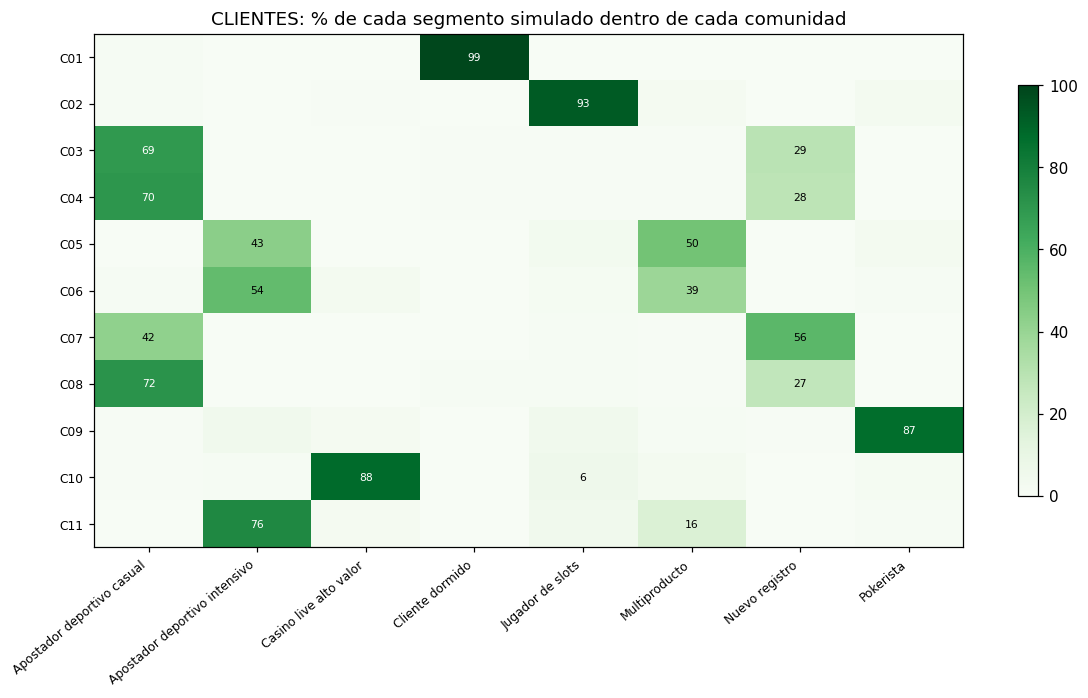

In [11]:
cruce = community_segment_crosstab(etiquetas, segments.loc[ids])
fig, ax = plt.subplots(figsize=(11, 0.45 * len(cruce) + 1.5))
im = ax.imshow(cruce.values, cmap="Greens", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(cruce.shape[1]), cruce.columns, rotation=40, ha="right", fontsize=8)
ax.set_yticks(range(cruce.shape[0]), cruce.index, fontsize=8)
for i in range(cruce.shape[0]):
    for j in range(cruce.shape[1]):
        v = cruce.iat[i, j]
        if v >= 5:
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=7, color="white" if v > 60 else "black")
ax.set_title(f"{PROYECTO}: % de cada segmento simulado dentro de cada comunidad")
fig.colorbar(im, ax=ax, shrink=0.8); plt.tight_layout(); plt.show()

### Perfil de cada comunidad

Rasgos calculados **sin usar el segmento simulado**:

- numéricas: percentil medio de la comunidad (↑ p90 = sus miembros están, de media, en el 10 % más alto);
- categóricas: categoría sobre-representada (% en la comunidad frente al % global).

Esta tabla es la que se enseñaría a negocio para poner nombre a cada comunidad.

In [12]:
perfiles = profile_communities(prep.processed_data_before_scaling, prep.variable_types, etiquetas,
                               segments, cfg.get("columnas_ejemplo"))
perfiles

,COMUNIDAD,N,PCT,RASGOS,SEGMENTO_DOMINANTE,PUREZA,MEDIANA_EDAD,MEDIANA_NUM_ACCESOS_30D,MEDIANA_TOTAL_DEPOSITADO_30D,MEDIANA_DIAS_DESDE_ULTIMO_ACCESO
0,C01,1988,19.9,↑ DIAS_DESDE_ULTIMO_DEPOSITO (p90) · ↑ DIAS_DESDE_ULTIMA_APUESTA (p90) · ↓ NUM_ACCESOS_90D (p10) · ↑ DIAS_DESDE_ULTIMO_ACCESO (p90),Cliente dormido,0.986,40.0,0.0,0.00,114.0
1,C02,1564,15.6,↑ NUM_SESIONES_CASINO_30D (p86) · PRODUCTO_FAVORITO = Casino (98% vs 37%) · ↑ TURNOVER_CASINO (p78) · ↓ PCT_APUESTAS_LIVE (p22),Jugador de slots,0.927,46.0,14.0,107.04,3.0
2,C03,1418,14.2,↓ TOTAL_DEPOSITADO (p28) · ↓ DIAS_DESDE_REGISTRO (p29) · ↓ TOTAL_RETIRADO (p29) · PRODUCTO_FAVORITO = Sports (92% vs 54%),Apostador deportivo casual,0.694,32.0,5.0,27.14,7.0
3,C04,1103,11.0,↓ OPEN_RATE_EMAIL (p14) · ↓ TOTAL_DEPOSITADO (p28) · PRODUCTO_FAVORITO = Sports (97% vs 54%) · ↓ DIAS_DESDE_REGISTRO (p29),Apostador deportivo casual,0.704,32.0,6.0,27.53,7.0
4,C05,979,9.8,↑ NUM_APUESTAS_SPORTS_30D (p87) · ↑ NUM_ACCESOS_90D (p83) · ↑ NUM_ACCESOS_30D (p82) · ↑ PCT_APUESTAS_LIVE (p80),Multiproducto,0.501,32.0,19.0,131.38,2.0
5,C06,913,9.1,↑ TURNOVER_SPORTS (p93) · ↑ TOTAL_DEPOSITADO_30D (p89) · ↑ NUM_APUESTAS_SPORTS_30D (p88) · ↑ TURNOVER_POKER (p86),Apostador deportivo intensivo,0.541,32.0,21.0,464.72,2.0
6,C07,530,5.3,↓ DIAS_DESDE_REGISTRO (p18) · ↓ TOTAL_DEPOSITADO (p19) · ↓ TOTAL_RETIRADO (p21) · ↓ NUM_APUESTAS_SPORTS_30D (p23),Nuevo registro,0.562,30.0,5.0,27.24,5.0
7,C08,529,5.3,↑ NUM_RETIROS_30D (p81) · ↓ TOTAL_DEPOSITADO (p29) · PRODUCTO_FAVORITO = Sports (95% vs 54%) · ↓ TOTAL_RETIRADO (p31),Apostador deportivo casual,0.715,31.0,6.0,29.37,7.0
8,C09,461,4.6,PRODUCTO_FAVORITO = Poker (99% vs 8%) · ↑ NGR_POKER (p94) · ↑ TURNOVER_POKER (p94) · ↑ TICKET_MEDIO (p84),Pokerista,0.868,33.0,18.0,163.59,2.0
9,C10,424,4.2,↑ TURNOVER_CASINO (p96) · ↑ TOTAL_DEPOSITADO_30D (p95) · ↑ TOTAL_DEPOSITADO (p95) · ↑ NUM_DEPOSITOS_30D (p94),Casino live alto valor,0.877,47.0,21.0,1562.74,2.0


### Proyección 2D (t-SNE sobre la distancia hybrid)

Muestra de 2.000 entidades. La distancia es exactamente la de la fase 1 (1 − similitud hybrid), calculada con
`dense_similarity`. A la izquierda, coloreado por comunidad; a la derecha, por segmento simulado.

t-SNE en 11.8s


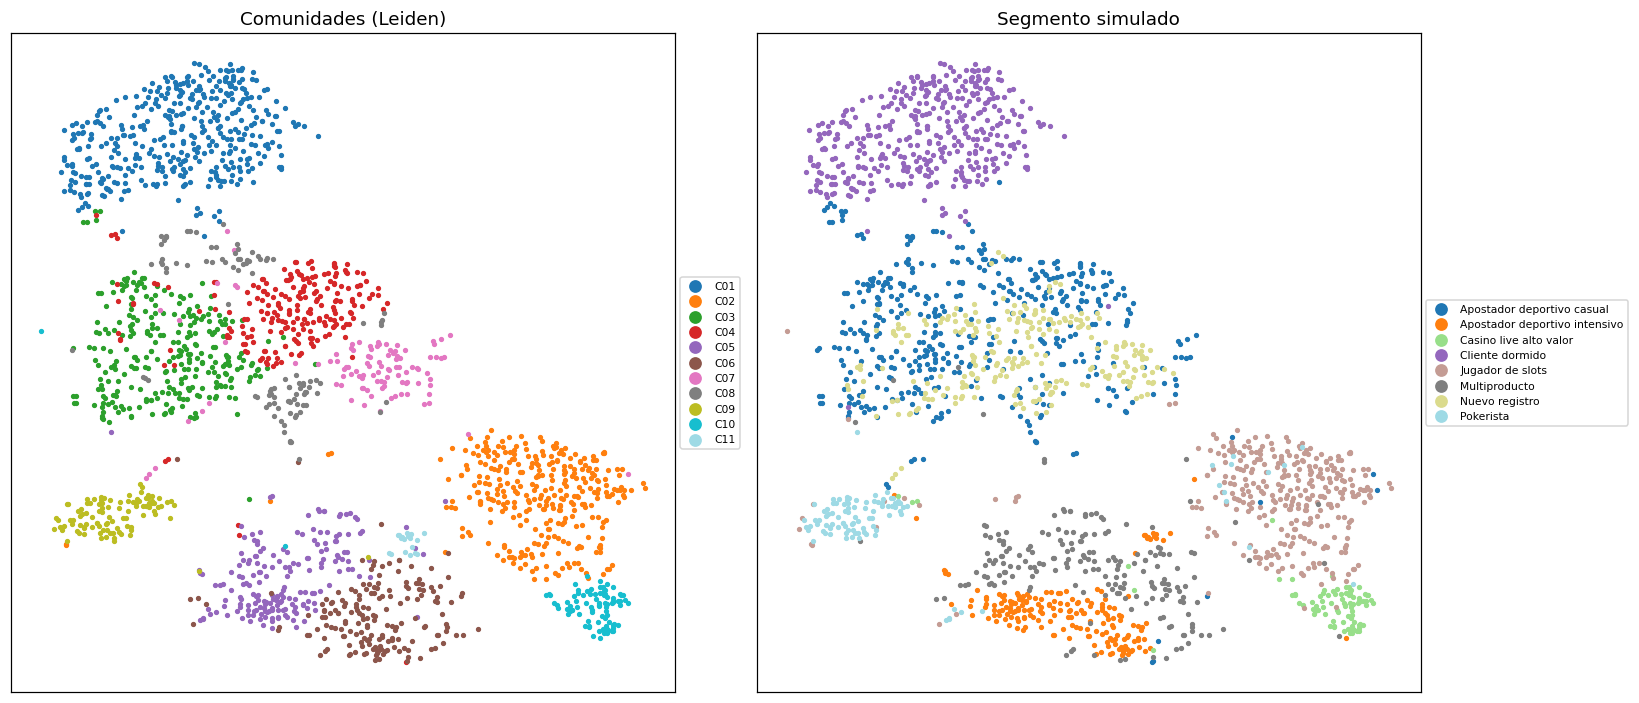

In [13]:
from sklearn.manifold import TSNE

rng = np.random.default_rng(0)
muestra = np.sort(rng.choice(ids, 2000, replace=False))
S = dense_similarity(X.loc[muestra], prep.variable_types, METRICA)
D = np.clip(1.0 - S, 0, None); np.fill_diagonal(D, 0)
t0 = time.time()
emb = TSNE(n_components=2, metric="precomputed", init="random", perplexity=40, random_state=0).fit_transform(D)
print(f"t-SNE en {time.time() - t0:.1f}s")

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
for ax, (lab, titulo) in zip(axes, [(etiquetas.loc[muestra], "Comunidades (Leiden)"),
                                    (segments.loc[muestra], "Segmento simulado")]):
    cats = sorted(lab.unique())
    cmap = plt.get_cmap("tab20", len(cats))
    for i, c in enumerate(cats):
        m = (lab == c).to_numpy()
        ax.scatter(emb[m, 0], emb[m, 1], s=6, color=cmap(i), label=c)
    ax.set_title(titulo); ax.set_xticks([]); ax.set_yticks([])
    ax.legend(markerscale=3, fontsize=7, loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout(); plt.show()

## 6. Resumen de la fase 2

In [14]:
leiden = comp_graph.iloc[0]
print(f"Proyecto: {PROYECTO}")
print(f"Grafo elegido: {elegido['grafo']} = {elegido['parametro']} ({g.ecount():,} aristas)")
print(f"Comunidades útiles: {int(leiden['comunidades'])} · cobertura {leiden['cobertura']:.1%} · "
      f"modularidad {leiden['modularidad']:.3f} · estabilidad {leiden['estabilidad']:.3f}")
print(f"Validación externa: ARI {leiden['ARI']:.3f} · NMI {leiden['NMI']:.3f}")
print(f"Configuración original: cobertura {ref['cobertura']:.1%} ({ref['pct_fuera_del_grafo']:.1%} fuera del grafo) · "
      f"ARI {ref['ARI']:.3f} · NMI {ref['NMI']:.3f}")

Proyecto: CLIENTES
Grafo elegido: knn = 15 (109,017 aristas)
Comunidades útiles: 11 · cobertura 100.0% · modularidad 0.777 · estabilidad 0.935
Validación externa: ARI 0.592 · NMI 0.666
Configuración original: cobertura 66.4% (28.5% fuera del grafo) · ARI 0.348 · NMI 0.508


**Conclusiones**

- El umbral global de producción deja fuera del grafo a una parte importante de las entidades, que no pueden
  recibir recomendación. El grafo de k vecinos cubre el 100 % con menos aristas.
- La configuración se elige sin mirar los segmentos simulados; aun así, las comunidades concuerdan con ellos
  bastante mejor que la configuración original.
- Frente al clustering clásico, las comunidades del grafo alcanzan un acuerdo similar a K-Means **sin necesitar
  el número de grupos**, que K-Means recibe como dato. HDBSCAN, basado en densidad, no separa bien perfiles que se solapan.
- Los perfiles grandes se dividen en subgrupos con sentido de negocio (horario, antigüedad del recanje, retiradas…),
  que la fase 3 usará para recomendar.